# Los Angeles Crime Data Analysis (2020 – 2024)

**Data:** [LA Open Data – Crime Data from 2020 to Present](https://data.lacity.org/Public-Safety/Crime-Data-from-2020-to-Present/2nrs-mtv8/about_data) (July 2025 snapshot, ~1M records). See the repository README for how to set up the `data/` folder.

**Data-quality findings that shape this analysis**
- **LAPD changed records systems on 7 March 2024.** The legacy system behind this dataset was retired, so recorded crimes drop by more than half from March 2024. That drop is a reporting artifact, not a real decline, so trends and the forecast use **January 2020 – February 2024**, and yearly comparisons use the complete years **2020–2023**.
- **Victim age 0 appears in ~27% of records**, mostly vehicle thefts and other crimes with no person victim. These are treated as *not recorded* rather than filled with invented ages.
- **No weapon is recorded for ~67% of crimes.** These are labelled *NO WEAPON RECORDED* instead of being filled with the most common weapon.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../data")

In [2]:
df = pd.read_csv(next(DATA_DIR.glob("Crime_Data_from_2020_to_Present*.csv")))
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,211507896,04/11/2021 12:00:00 AM,11/07/2020 12:00:00 AM,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092
1,201516622,10/21/2020 12:00:00 AM,10/18/2020 12:00:00 AM,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",...,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203
2,240913563,12/10/2024 12:00:00 AM,10/30/2020 12:00:00 AM,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509
3,210704711,12/24/2020 12:00:00 AM,12/24/2020 12:00:00 AM,1310,7,Wilshire,782,1,331,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,...,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747
4,201418201,10/03/2020 12:00:00 AM,09/29/2020 12:00:00 AM,1830,14,Pacific,1454,1,420,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),...,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350


# Data Inspection:
- Display the first few rows of the dataset.
- Check the data types of each column.
- Review column names and descriptions, if available.

In [3]:
#Display the first few rows of the dataset.
df.head(12)

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,211507896,04/11/2021 12:00:00 AM,11/07/2020 12:00:00 AM,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092
1,201516622,10/21/2020 12:00:00 AM,10/18/2020 12:00:00 AM,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",...,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203
2,240913563,12/10/2024 12:00:00 AM,10/30/2020 12:00:00 AM,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509
3,210704711,12/24/2020 12:00:00 AM,12/24/2020 12:00:00 AM,1310,7,Wilshire,782,1,331,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,...,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747
4,201418201,10/03/2020 12:00:00 AM,09/29/2020 12:00:00 AM,1830,14,Pacific,1454,1,420,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),...,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350
5,240412063,12/11/2024 12:00:00 AM,11/11/2020 12:00:00 AM,1210,4,Hollenbeck,429,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,5300 CRONUS ST,NaN,34.0830,-118.1678
6,240317069,12/16/2024 12:00:00 AM,04/16/2020 12:00:00 AM,1350,3,Southwest,396,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,900 W 40TH PL,NaN,34.0100,-118.2900
7,201115217,10/29/2020 12:00:00 AM,07/07/2020 12:00:00 AM,1400,11,Northeast,1133,2,812,CRM AGNST CHLD (13 OR UNDER) (14-15 & SUSP 10 ...,...,AO,Adult Other,812.0,860.0,NaN,NaN,3000 ACRESITE ST,NaN,34.1107,-118.2589
8,241708596,04/20/2024 12:00:00 AM,03/02/2020 12:00:00 AM,1200,17,Devonshire,1729,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,17700 SIMONDS ST,NaN,34.2763,-118.5210
9,242113813,12/18/2024 12:00:00 AM,09/01/2020 12:00:00 AM,900,21,Topanga,2196,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,20900 MARMORA ST,NaN,34.1493,-118.5886


In [4]:
# list out the column names
df.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON'],
      dtype='str')

In [5]:
# column data types, info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004991 entries, 0 to 1004990
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004991 non-null  int64  
 1   Date Rptd       1004991 non-null  str    
 2   DATE OCC        1004991 non-null  str    
 3   TIME OCC        1004991 non-null  int64  
 4   AREA            1004991 non-null  int64  
 5   AREA NAME       1004991 non-null  str    
 6   Rpt Dist No     1004991 non-null  int64  
 7   Part 1-2        1004991 non-null  int64  
 8   Crm Cd          1004991 non-null  int64  
 9   Crm Cd Desc     1004991 non-null  str    
 10  Mocodes         853372 non-null   str    
 11  Vict Age        1004991 non-null  int64  
 12  Vict Sex        860347 non-null   str    
 13  Vict Descent    860335 non-null   str    
 14  Premis Cd       1004975 non-null  float64
 15  Premis Desc     1004403 non-null  str    
 16  Weapon Used Cd  327247 non-null   float64
 17  

In [6]:
# defines number of rows and columns in the dataset
df.shape

(1004991, 28)

# Data Cleaning:
- Identify and handle missing data appropriately.
- Check for and remove duplicate rows.
- Convert data types if needed (e.g., dates to date format, numerical values to appropriate numeric types).
- Deal with outliers if relevant to your analysis.
- Standardize or normalize numerical data as necessary.
- Encode categorical data if present

In [7]:
## creating a datframe for descriptions and types, sample value of each column
infoData={
    "column":[],
    "value":[],
    "dtype":[],
    "descriptions":["""Division of Records Number: Official file number made up of a 2 digit year, area ID, and 5 digits""",	
"""MM/DD/YYYY""","""MM/DD/YYYY""","""In 24 hour military time.""","""	The LAPD has 21 Community Police Stations referred to as Geographic Areas within the department. These Geographic Areas are sequentially numbered from 1-21.""",
"""The 21 Geographic Areas or Patrol Divisions are also given a name designation that references a landmark or the surrounding community that it is responsible for. For example 77th Street Division is located at the intersection of South Broadway and 77th Street, serving neighborhoods in South Los Angeles.""",
"""A four-digit code that represents a sub-area within a Geographic Area. All crime records reference the 'RD' that it occurred in for statistical comparisons. Find LAPD Reporting Districts on the LA City GeoHub at http://geohub.lacity.org/datasets/c4f83909b81d4786aa8ba8a74a4b4db1_4""","""""",	
"""Indicates the crime committed. (Same as Crime Code 1)""","""Defines the Crime Code provided.""","""Modus Operandi: Activities associated with the suspect in commission of the crime.See attached PDF for list of MO Codes in numerical order. https://data.lacity.org/api/views/y8tr-7khq/files/3a967fbd-f210-4857-bc52-60230efe256c?download=true&filename=MO%20CODES%20(numerical%20order).pdf""","""Two character numeric""","""F - Female M - Male X - Unknown""","""Descent Code: A - Other Asian B - Black C - Chinese D - Cambodian F - Filipino G - Guamanian H - Hispanic/Latin/Mexican I - American Indian/Alaskan Native J - Japanese K - Korean L - Laotian O - Other P - Pacific Islander S - Samoan U - Hawaiian V - Vietnamese W - White X - Unknown Z - Asian Indian""",
"""The type of structure, vehicle, or location where the crime took place.""","""Defines the Premise Code provided.""","""The type of weapon used in the crime.""","""Defines the Weapon Used Code provided.""","""Status of the case. (IC is the default)""","""Defines the Status Code provided.""","""	Indicates the crime committed. Crime Code 1 is the primary and most serious one. Crime Code 2, 3, and 4 are respectively less serious offenses. Lower crime class numbers are more serious.""","""May contain a code for an additional crime, less serious than Crime Code 1.""","""May contain a code for an additional crime, less serious than Crime Code 1""","""	May contain a code for an additional crime, less serious than Crime Code 1.""","""Street address of crime incident rounded to the nearest hundred block to maintain anonymity.""","""Cross Street of rounded Address""","""	Latitude""","""	Longtitude"""]
}
for column in df.columns:
    infoData['column'].append(column)
    infoData['value'].append(df[column].loc[0])
    infoData['dtype'].append(df[column].dtype)
infoData=pd.DataFrame(infoData)
infoData

,column,value,dtype,descriptions
0,DR_NO,211507896,int64,Division of Records Number: Official file numb...
1,Date Rptd,04/11/2021 12:00:00 AM,str,MM/DD/YYYY
2,DATE OCC,11/07/2020 12:00:00 AM,str,MM/DD/YYYY
3,TIME OCC,845,int64,In 24 hour military time.
4,AREA,15,int64,\tThe LAPD has 21 Community Police Stations re...
5,AREA NAME,N Hollywood,str,The 21 Geographic Areas or Patrol Divisions ar...
6,Rpt Dist No,1502,int64,A four-digit code that represents a sub-area w...
7,Part 1-2,2,int64,
8,Crm Cd,354,int64,Indicates the crime committed. (Same as Crime ...
9,Crm Cd Desc,THEFT OF IDENTITY,str,Defines the Crime Code provided.


In [8]:
# identify the misssing values
df.isna().sum()

DR_NO                   0
Date Rptd               0
DATE OCC                0
TIME OCC                0
AREA                    0
AREA NAME               0
Rpt Dist No             0
Part 1-2                0
Crm Cd                  0
Crm Cd Desc             0
Mocodes            151619
Vict Age                0
Vict Sex           144644
Vict Descent       144656
Premis Cd              16
Premis Desc           588
Weapon Used Cd     677744
Weapon Desc        677744
Status                  1
Status Desc             0
Crm Cd 1               11
Crm Cd 2           935831
Crm Cd 3          1002677
Crm Cd 4          1004927
LOCATION                0
Cross Street       850755
LAT                     0
LON                     0
dtype: int64

In [9]:
# remove duplicate rows
df.drop_duplicates(inplace=True)
df.shape

/var/folders/67/ycsyff756wlbwt4r7qbj8__00000gn/T/ipykernel_18774/2192146252.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


(1004991, 28)

In [10]:
# find all the columns which have empty or nan values
nullCols=df.apply(lambda col: col.isnull().sum()>0)
emptyColumnNames,emptyColumns=[],[]
for index, value in nullCols.items():
    if value == True:
        emptyColumns.append((index,df[index].dtype))
        emptyColumnNames.append(index)
emptyColumnNames

['Mocodes',
 'Vict Sex',
 'Vict Descent',
 'Premis Cd',
 'Premis Desc',
 'Weapon Used Cd',
 'Weapon Desc',
 'Status',
 'Crm Cd 1',
 'Crm Cd 2',
 'Crm Cd 3',
 'Crm Cd 4',
 'Cross Street']

In [11]:
#descriptive statistics of empty columns
descriptive_statistics=df[emptyColumnNames].describe(include='all')
descriptive_statistics

,Mocodes,Vict Sex,Vict Descent,Premis Cd,Premis Desc,Weapon Used Cd,Weapon Desc,Status,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,Cross Street
count,853372,860347,860335,1.004975e+06,1004403,327247.000000,327247,1004990,1.004980e+06,69160.000000,2314.000000,64.00000,154236
unique,310939,5,20,NaN,306,NaN,79,6,NaN,NaN,NaN,NaN,10413
top,0344,M,H,NaN,STREET,NaN,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,NaN,NaN,NaN,NaN,BROADWAY
freq,42187,403879,296404,NaN,261284,NaN,174761,802884,NaN,NaN,NaN,NaN,2486
mean,NaN,NaN,NaN,3.056201e+02,NaN,363.955300,NaN,NaN,4.999174e+02,958.101258,984.015990,991.21875,NaN
std,NaN,NaN,NaN,2.193021e+02,NaN,123.734528,NaN,NaN,2.050736e+02,110.354348,52.350982,27.06985,NaN
min,NaN,NaN,NaN,1.010000e+02,NaN,101.000000,NaN,NaN,1.100000e+02,210.000000,310.000000,821.00000,NaN
25%,NaN,NaN,NaN,1.010000e+02,NaN,311.000000,NaN,NaN,3.310000e+02,998.000000,998.000000,998.00000,NaN
50%,NaN,NaN,NaN,2.030000e+02,NaN,400.000000,NaN,NaN,4.420000e+02,998.000000,998.000000,998.00000,NaN
75%,NaN,NaN,NaN,5.010000e+02,NaN,400.000000,NaN,NaN,6.260000e+02,998.000000,998.000000,998.00000,NaN


In [12]:
# seperate the numerical, other type columns

numericEmptyColumns=df[emptyColumnNames].select_dtypes(include=["int64","float64"]).columns
otherEmptyColumns=df[emptyColumnNames].select_dtypes(exclude="number").columns
numericEmptyColumns,otherEmptyColumns

(Index(['Premis Cd', 'Weapon Used Cd', 'Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3',
        'Crm Cd 4'],
       dtype='str'),
 Index(['Mocodes', 'Vict Sex', 'Vict Descent', 'Premis Desc', 'Weapon Desc',
        'Status', 'Cross Street'],
       dtype='str'))

In [13]:
# Numeric columns with missing values here are ID codes (premise, weapon, secondary crime codes).
# The mean of a code is meaningless, so they are left as missing.
# For text columns, "missing" is information in itself, so it is labelled rather than guessed.
df[otherEmptyColumns] = df[otherEmptyColumns].fillna("Unknown")
df["Weapon Desc"] = df["Weapon Desc"].replace("Unknown", "NO WEAPON RECORDED")

In [14]:
# check whether if any other rows have na values after cleaning
df.isnull().sum()

DR_NO                   0
Date Rptd               0
DATE OCC                0
TIME OCC                0
AREA                    0
AREA NAME               0
Rpt Dist No             0
Part 1-2                0
Crm Cd                  0
Crm Cd Desc             0
Mocodes                 0
Vict Age                0
Vict Sex                0
Vict Descent            0
Premis Cd              16
Premis Desc             0
Weapon Used Cd     677744
Weapon Desc             0
Status                  0
Status Desc             0
Crm Cd 1               11
Crm Cd 2           935831
Crm Cd 3          1002677
Crm Cd 4          1004927
LOCATION                0
Cross Street            0
LAT                     0
LON                     0
dtype: int64

In [15]:
otherTypeColumnNames=df.select_dtypes(include="object").columns
for column in otherTypeColumnNames:
    categoryCount=df[column].value_counts()
    # if categoryCount.count()<1000:
        # print(column,'---',categoryCount)
otherTypeColumnNames

/var/folders/67/ycsyff756wlbwt4r7qbj8__00000gn/T/ipykernel_18774/145814689.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  otherTypeColumnNames=df.select_dtypes(include="object").columns


Index(['Date Rptd', 'DATE OCC', 'AREA NAME', 'Crm Cd Desc', 'Mocodes',
       'Vict Sex', 'Vict Descent', 'Premis Desc', 'Weapon Desc', 'Status',
       'Status Desc', 'LOCATION', 'Cross Street'],
      dtype='str')

In [16]:
# Victim age 0 (or below) is LAPD's placeholder when there is no person victim
# (e.g. a stolen vehicle or a business) or the age was not recorded.
# Treat it as missing instead of inventing ages; demographic charts use recorded ages only.
print("Records with victim age <= 0:", (df['Vict Age'] <= 0).sum())
df['Vict Age'] = df['Vict Age'].where(df['Vict Age'].between(1, 100))

# Victim sex: LAPD codes are F, M and X (unknown). Anything else is mapped to X.
df['Vict Sex'] = df['Vict Sex'].where(df['Vict Sex'].isin(['F', 'M', 'X']), 'X')
df['Vict Sex'].value_counts()

Records with victim age <= 0: 269359


Vict Sex
M    403879
F    358580
X    242532
Name: count, dtype: int64

In [17]:
#Changing 'Date Rptd' Format
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'],format='%m/%d/%Y %I:%M:%S %p')
df['Date Rptd'] = df['Date Rptd'].dt.date

# Changing 'Date OCC' format
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'],format='%m/%d/%Y %I:%M:%S %p')
df['DATE OCC']=df['DATE OCC'].dt.date

# 4. Exploratory Data Analysis (EDA):-  Visualize overall crime trends from 2020 to the present year.- - Analyze and visualize seasonal patterns in crime data- 
- Identify the most common type of crime and its trends over tim- 
- Investigate if there are any notable differences in crime rates between regions or 
cit- s.
- Explore correlations between economic factors (if available) and crime r- es.
- Analyze the relationship between the day of the week and the frequency of certain 
types of - imes.
- Investigate any impact of significant events or policy changes on crime rates

In [18]:
#Visualize overall crime trends from 2020 to the present year.- - Analyze and visualize seasonal patterns in crime data-


df['DATE OCC']=pd.to_datetime(df['DATE OCC'])
df['Year'] = df['DATE OCC'].dt.year
df['Month']=df['DATE OCC'].dt.month_name()


In [19]:
#Changing 'TIME OCC' format
df['TIME OCC'] = df['TIME OCC'].astype(str).str.zfill(4)
df['TIME OCC'] = pd.to_datetime(df['TIME OCC'], format = '%H%M').dt.time
df['TIME OCC']

0          08:45:00
1          18:45:00
2          12:40:00
3          13:10:00
4          18:30:00
             ...   
1004986    01:30:00
1004987    10:00:00
1004988    15:54:00
1004989    16:00:00
1004990    12:35:00
Name: TIME OCC, Length: 1004991, dtype: object

## Data check: LAPD's March 2024 records-system change
Before analysing trends, check that monthly volumes are consistent across the whole period.

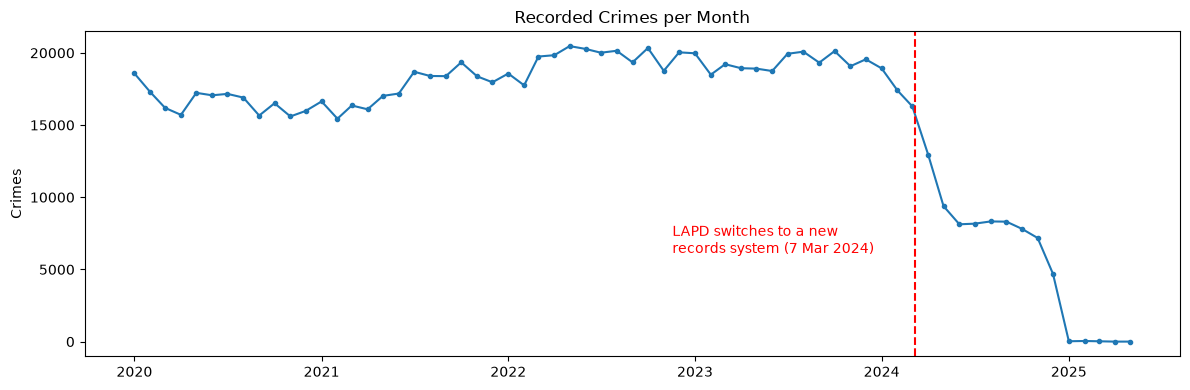

Average monthly records, Mar 2023 – Feb 2024: 19,184
Average monthly records, Apr 2024 – Nov 2024: 8,782 (-54%)


In [20]:
monthly = df.groupby(df['DATE OCC'].dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, marker='o', markersize=3)
switch = pd.Timestamp('2024-03-07')
ax.axvline(switch, color='red', linestyle='--')
ax.annotate('LAPD switches to a new\nrecords system (7 Mar 2024)', xy=(switch, monthly.max() * 0.3),
            xytext=(-175, 0), textcoords='offset points', color='red')
ax.set_title('Recorded Crimes per Month')
ax.set_ylabel('Crimes')
plt.tight_layout()
plt.show()

before = monthly['2023-03':'2024-02'].mean()
after = monthly['2024-04':'2024-11'].mean()
print(f"Average monthly records, Mar 2023 – Feb 2024: {before:,.0f}")
print(f"Average monthly records, Apr 2024 – Nov 2024: {after:,.0f} ({after / before - 1:+.0%})")

The drop is a reporting artifact. LAPD's note on the dataset page explains that the legacy records system was retired after the switch to NIBRS reporting, and new incidents are published in separate NIBRS datasets instead. So:
- **trend and forecasting sections use January 2020 – February 2024** (`df_trend`)
- **year-level comparisons use the complete years 2020–2023** (`df_full_years`)
- category breakdowns (crime type, area, victim) use all records

In [21]:
TREND_END = '2024-02-29'
df_trend = df[df['DATE OCC'] <= TREND_END]
df_full_years = df[df['Year'].between(2020, 2023)]
df['Day'] = df['DATE OCC'].dt.day_name()
df_full_years = df_full_years.assign(Day=df_full_years['DATE OCC'].dt.day_name())
print(f"df_trend: {len(df_trend):,} records | df_full_years: {len(df_full_years):,} records")

df_trend: 913,647 records | df_full_years: 877,327 records


# 1. Overall Crime Trends:
• Calculate and plot the total number of crimes per year to visualize the trends.

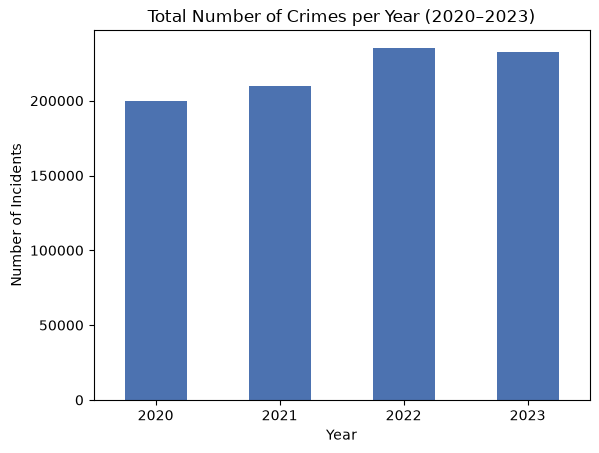

Year
2020    199847
2021    209876
2022    235259
2023    232345
Name: count, dtype: int64

In [22]:
# Year-wise crime totals (complete years only, before the records-system change)
crime_freq_by_year = df_full_years['Year'].value_counts().sort_index()

crime_freq_by_year.plot(kind='bar', color='#4C72B0')
plt.title('Total Number of Crimes per Year (2020–2023)')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=0)
plt.show()
crime_freq_by_year

# 2. Seasonal Patterns:
• Group the data by month and analyze the average number of monthly crimes over 
the years

,Month,Count
4,January,18437.25
3,February,17240.75
7,March,17875.25
0,April,17642.75
8,May,18406.25
6,June,18314.00
5,July,18948.00
1,August,18881.50
11,September,18176.50
10,October,19077.50


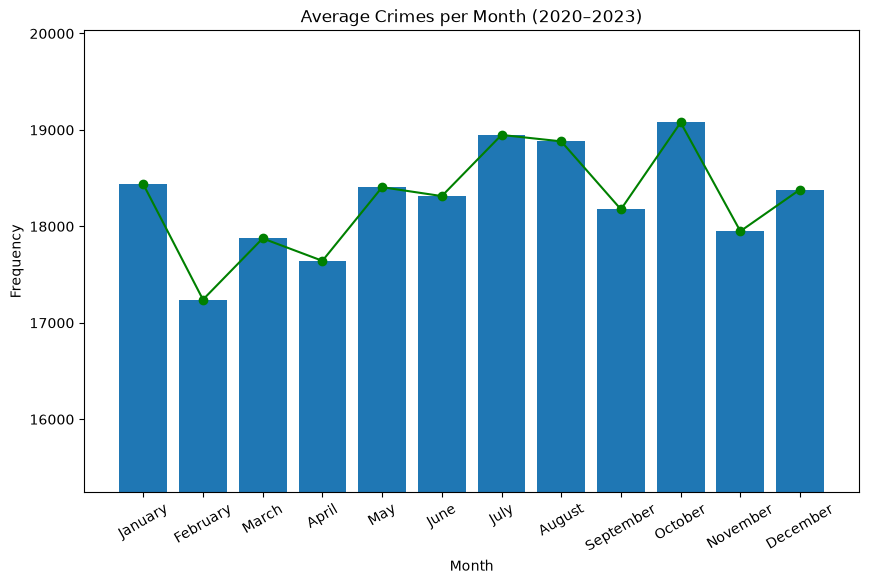

In [23]:
months=['January','February','March','April','May','June','July',"August",'September','October',"November",'December']
averageCrimesPerMonth = df_full_years.groupby(['Year', 'Month']).size().groupby('Month').mean().reset_index(name='Count')

averageCrimesPerMonth['Month'] = pd.Categorical(averageCrimesPerMonth['Month'], categories=months, ordered=True)
averageCrimesPerMonth = averageCrimesPerMonth.sort_values('Month')
plt.figure(figsize=(10, 6))
plt.plot(averageCrimesPerMonth['Month'],averageCrimesPerMonth['Count'], marker='o', linestyle='-', color='green')
plt.bar(averageCrimesPerMonth['Month'],averageCrimesPerMonth['Count'])
plt.xticks(months,rotation=30)
plt.xlabel("Month")
plt.ylabel("Frequency")
plt.title("Average Crimes per Month (2020–2023)")
plt.ylim(min(averageCrimesPerMonth['Count'])-2000)
averageCrimesPerMonth

# 3. Most Common Crime Type:
• Count the occurrences of each crime type and identify the one with the highest 
frequencynce

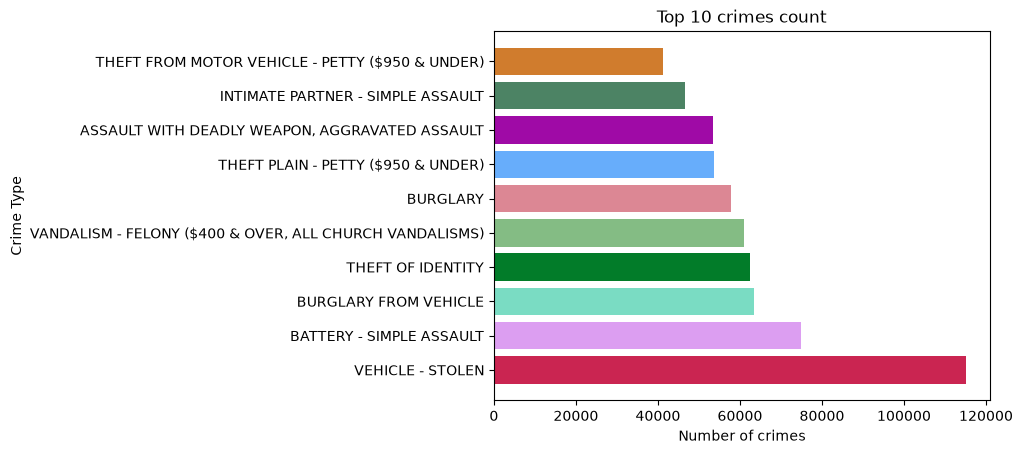

(Crm Cd Desc
 VEHICLE - STOLEN                                           115190
 BATTERY - SIMPLE ASSAULT                                    74839
 BURGLARY FROM VEHICLE                                       63517
 THEFT OF IDENTITY                                           62537
 VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)     61092
 BURGLARY                                                    57871
 THEFT PLAIN - PETTY ($950 & UNDER)                          53717
 ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT              53525
 INTIMATE PARTNER - SIMPLE ASSAULT                           46712
 THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)             41314
 Name: count, dtype: int64,
 140)

In [24]:
# Identify the most common type of crime and its trends over time
import matplotlib.patches as mpatches
crimes=df['Crm Cd Desc'].value_counts()
fig,ax=plt.subplots()
colors=['#CA2551', '#DC9EF1', '#7ADCC3', '#027C29', '#84BC84', '#DC8794', '#67ADFB', '#9F0AA6', '#4C8364', '#D07C2D']
ax.barh(crimes.index[:10],crimes.values[:10], align='center',color=colors)
plt.xlabel("Number of crimes")
plt.ylabel("Crime Type")
plt.title("Top 10 crimes count")
# patches = [mpatches.Patch(color=colors[i], label=crimes.index[i]) for i in range(10)]
# plt.legend(handles=patches, title="Crime Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()
crimes[:10],len(crimes)


From the above bar chart we can observe that most common crime is "vehicle stolen"

In [25]:
vehicleStolenCrimes = df_full_years[df_full_years['Crm Cd Desc'] == 'VEHICLE - STOLEN']

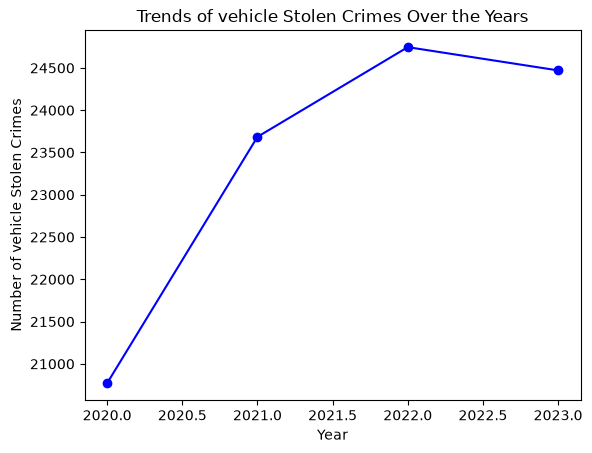

In [26]:
#Identify the most common type of crime and its trends over tim-
crime_trends = vehicleStolenCrimes.groupby('Year').size()

# Step 4: Plot the crime trends over time
fig, ax = plt.subplots()
ax.plot(crime_trends.index, crime_trends.values, marker='o', linestyle='-', color='b')

# Add labels and title
plt.xlabel('Year')
plt.ylabel(f'Number of vehicle Stolen Crimes')
plt.title(f'Trends of vehicle Stolen Crimes Over the Years')

# Show the plot
plt.show()

# 4. Regional Differences:
• Group the data by region or city and compare crime rates using descriptive statistics 
or visualizations.

In [27]:
areaWise_crimes= df.groupby('AREA NAME')
areaWise_crimes['AREA NAME'].size()

AREA NAME
77th Street    61758
Central        69670
Devonshire     41756
Foothill       33133
Harbor         41394
Hollenbeck     37085
Hollywood      52429
Mission        40351
N Hollywood    51107
Newton         49177
Northeast      42963
Olympic        50071
Pacific        59514
Rampart        46825
Southeast      49936
Southwest      57441
Topanga        41374
Van Nuys       42883
West LA        45729
West Valley    42156
Wilshire       48239
Name: AREA NAME, dtype: int64

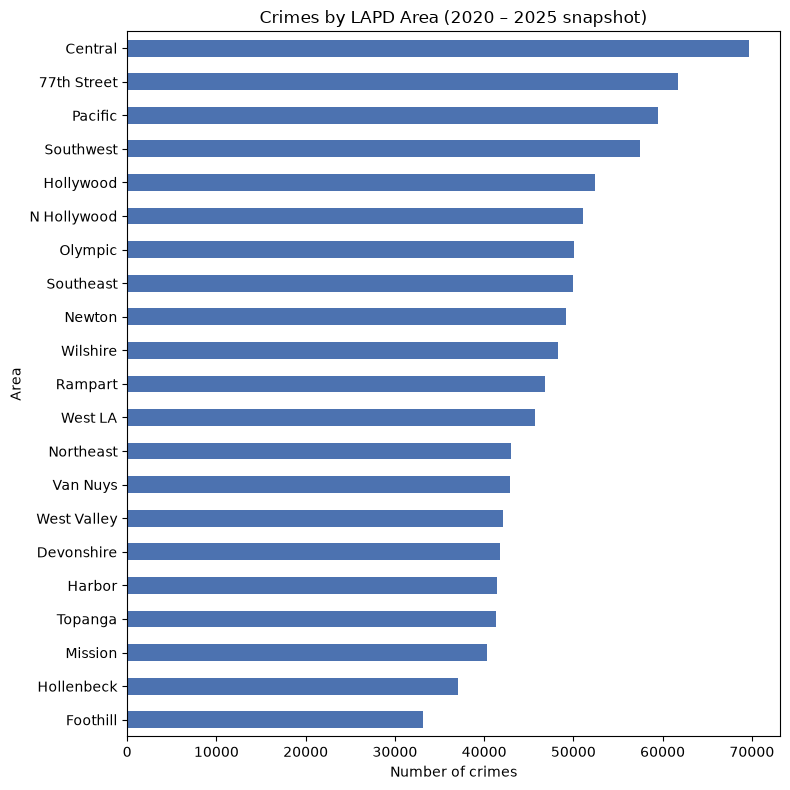

Year,2020,2021,2022,2023
AREA NAME,,,,
77th Street,13353,13102,14573,13953
Central,11604,13171,17715,16966
Devonshire,7984,8507,9597,9776
Foothill,7107,7048,7867,7160
Harbor,8875,8875,9200,9135
Hollenbeck,7807,8029,8522,8410
Hollywood,10174,12109,12546,11448
Mission,8482,8238,9281,8981
N Hollywood,10169,10932,11200,11557


In [28]:
# Crimes per LAPD area, sorted
area_counts = df['AREA NAME'].value_counts().sort_values()
area_counts.plot(kind='barh', figsize=(8, 8), color='#4C72B0')
plt.xlabel("Number of crimes")
plt.ylabel("Area")
plt.title("Crimes by LAPD Area (2020 – 2025 snapshot)")
plt.tight_layout()
plt.show()

# Area-wise crimes by year
areaWise_crimes_year = df_full_years.groupby(['AREA NAME', 'Year']).size().unstack()
areaWise_crimes_year

In [29]:
import folium

# LAT/LON of 0 means the location was not geocoded; exclude those
geo = df[(df['LAT'] != 0) & (df['LON'] != 0)]
locationWiseCrimes = (geo.groupby(['LAT', 'LON', 'LOCATION']).size()
                      .reset_index(name='Crimes Count')
                      .sort_values(by='Crimes Count', ascending=False))

# Interactive map of the 100 busiest locations (saved as HTML; GitHub can't display it inline)
crime_map = folium.Map(location=[geo['LAT'].mean(), geo['LON'].mean()], tiles="CartoDB Positron", zoom_start=10)
for _, row in locationWiseCrimes.head(100).iterrows():
    folium.Marker(location=[row['LAT'], row['LON']], popup=row['LOCATION']).add_to(crime_map)
crime_map.save('crimesmap.html')

locationWiseCrimes.head(10)

/private/tmp/claude-501/-Users-raghu/2125a7b1-172a-4a99-a362-742619829bee/scratchpad/work/.venv/lib/python3.12/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


,LAT,LON,LOCATION,Crimes Count
79788,34.0561,-118.2375,800 N ALAMEDA ST,2396
72518,34.0483,-118.2631,700 S FIGUEROA ST,1657
66548,34.0428,-118.4582,11800 SANTA MONICA BL,1448
150288,34.2440,-118.5583,9300 TAMPA AV,1434
91312,34.0736,-118.3563,100 THE GROVE DR,1362
83520,34.0611,-118.4184,10200 SANTA MONICA BL,1302
82302,34.0595,-118.2749,600 S ALVARADO ST,1145
130390,34.1904,-118.6059,6600 TOPANGA CANYON BL,1130
87390,34.0669,-118.3456,400 S LA BREA AV,1036
14830,33.9455,-118.4001,300 WORLD WY,870


# 5. Correlation with Economic Factors:
• Collect economic data for the same time frame and use statistical methods, such as 
correlation analysis, to assess the relationship between economic factors and crime 
rates

In [30]:
# LA Controller – All City Funds: https://controllerdata.lacity.org/d/ej7u-di9z
cityFunds = pd.read_csv(DATA_DIR / "All_City_Funds.csv")

In [31]:
cityFunds['Fund Effective Date']=pd.to_datetime(cityFunds['Fund Effective Date'])
cityFunds['Year']=cityFunds['Fund Effective Date'].dt.year
cityFunds = cityFunds[(cityFunds['Year'] >= 2020) & (cityFunds['Year'] <= 2024)]



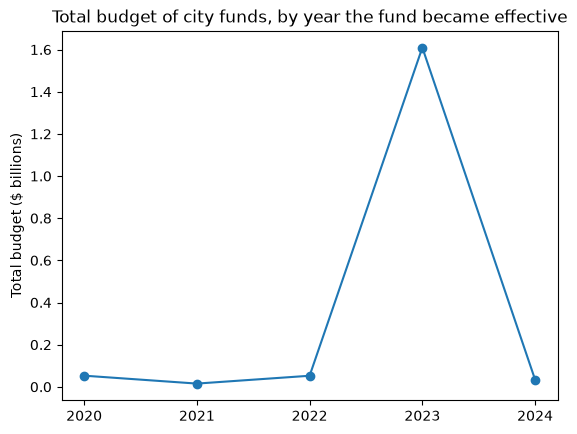

Year
2020    5.289232e+07
2021    1.534637e+07
2022    5.252151e+07
2023    1.609494e+09
2024    3.437245e+07
Name: Total Budget, dtype: float64

In [32]:
YearWiseBudget = cityFunds.groupby('Year')['Total Budget'].sum()
plt.plot(YearWiseBudget.index, YearWiseBudget / 1e9, marker='o')
plt.title('Total budget of city funds, by year the fund became effective')
plt.ylabel('Total budget ($ billions)')
plt.xticks(YearWiseBudget.index)
plt.show()
YearWiseBudget

**Limitation:** *Fund Effective Date* is when each fund was established, so this chart sums the budgets of funds *created* in each year. It is not the city's annual spending, and with only five yearly points no meaningful correlation with crime can be estimated. A proper comparison would use the city's adopted annual budget by department (e.g. LAPD) against the crime counts above.

# 6. Day of the Week Analysis:
• Group the data by day of the week and analyze crime frequencies for each day.

In [33]:

df['Day']=pd.to_datetime(df['DATE OCC']).dt.day_name()
daysWiseCrimesOverYears=df.groupby(['Year','Day']).size()
daysCrimes=daysWiseCrimesOverYears.groupby('Day').sum()
daysCrimes,daysWiseCrimesOverYears


(Day
 Friday       153676
 Monday       141543
 Saturday     147459
 Sunday       139648
 Thursday     141810
 Tuesday      138141
 Wednesday    142714
 dtype: int64,
 Year  Day      
 2020  Friday       29942
       Monday       28306
       Saturday     28955
       Sunday       27662
       Thursday     28281
       Tuesday      27633
       Wednesday    29068
 2021  Friday       32385
       Monday       30347
       Saturday     30308
       Sunday       29394
       Thursday     29428
       Tuesday      28564
       Wednesday    29450
 2022  Friday       36266
       Monday       32520
       Saturday     35348
       Sunday       32362
       Thursday     33245
       Tuesday      32359
       Wednesday    33159
 2023  Friday       35501
       Monday       32543
       Saturday     33863
       Sunday       32946
       Thursday     32594
       Tuesday      31873
       Wednesday    33025
 2024  Friday       19569
       Monday       17816
       Saturday     18983
       Sun

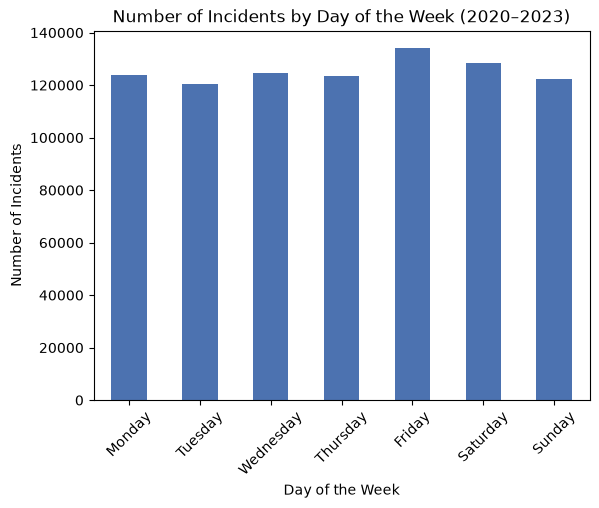

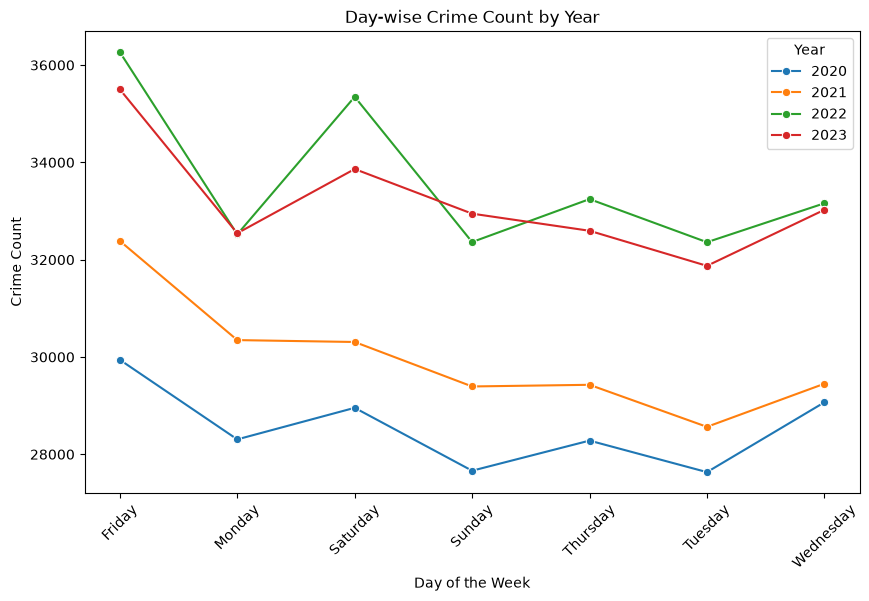

Day
Monday       123716
Tuesday      120429
Wednesday    124702
Thursday     123548
Friday       134094
Saturday     128474
Sunday       122364
Name: count, dtype: int64

In [34]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daysCrimesOfAllYears = df_full_years['Day'].value_counts().reindex(days)

daysCrimesOfAllYears.plot(kind='bar', color='#4C72B0')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Incidents')
plt.title('Number of Incidents by Day of the Week (2020–2023)')
plt.xticks(rotation=45)
plt.show()

# One line per year, days in calendar order
day_year = df_full_years.groupby(['Year', 'Day']).size().reset_index(name='Crime Count')
plt.figure(figsize=(10, 6))
sns.lineplot(data=day_year, x='Day', y='Crime Count', hue='Year', marker='o', palette='tab10')
plt.xticks(rotation=45)
plt.title('Day-wise Crime Count by Year')
plt.xlabel('Day of the Week')
plt.legend(title='Year')
plt.show()

daysCrimesOfAllYears

In [35]:
df['Time'] = pd.to_datetime(df['TIME OCC'], format='%H:%M:%S').dt.strftime('%H:%M')


df['Time_date'] = pd.to_datetime(df['Time'], format='%H:%M')

# Hour of day (floor, not round: most times are logged on the hour or half-hour, and rounding
# sends every :30 time to the nearest *even* hour, creating a false zigzag pattern)
df['RoundedTime'] = df['Time_date'].dt.floor('h').dt.strftime('%H:%M')

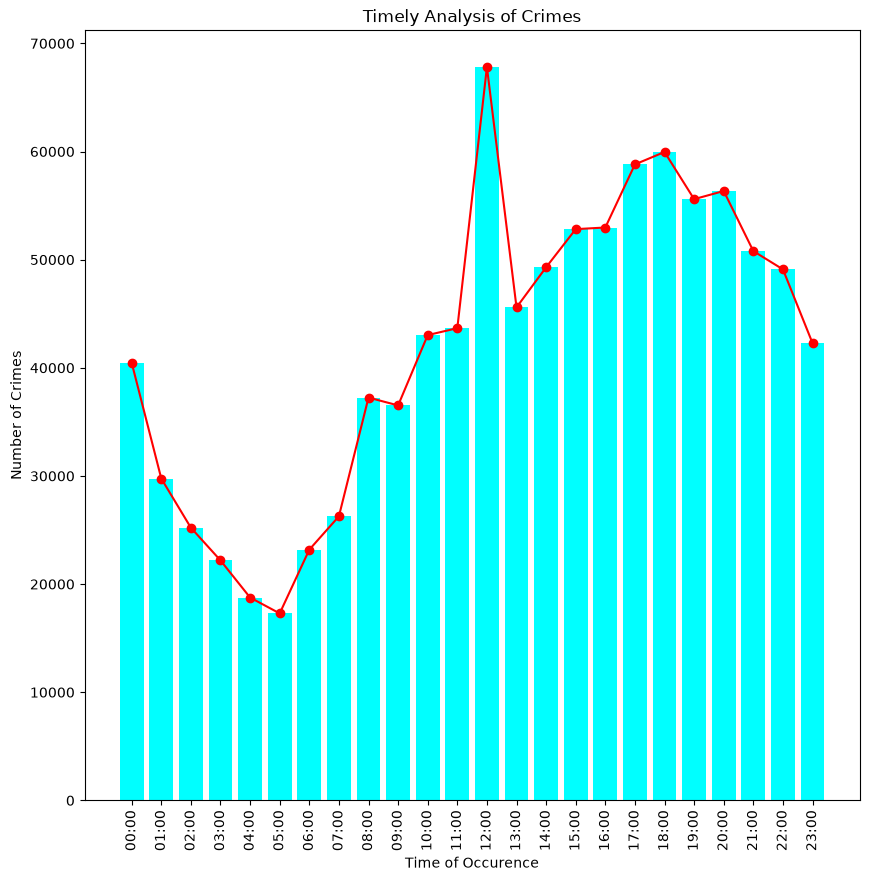

RoundedTime
00:00    40468
01:00    29761
02:00    25214
03:00    22191
04:00    18757
05:00    17290
06:00    23185
07:00    26267
08:00    37249
09:00    36524
10:00    43027
11:00    43666
12:00    67813
13:00    45587
14:00    49301
15:00    52824
16:00    52976
17:00    58811
18:00    59958
19:00    55597
20:00    56350
21:00    50793
22:00    49103
23:00    42279
dtype: int64

In [36]:
plt.figure(figsize=(10,10))
timeCounts=df.groupby('RoundedTime').size()
plt.plot(timeCounts.index,timeCounts.values,marker='o',color='r')
plt.bar(timeCounts.index,timeCounts.values,color='#00FFFF')
plt.xticks(rotation=90)
plt.ylabel("Number of Crimes")
plt.xlabel("Time of Occurence")
plt.title("Timely Analysis of Crimes")
plt.savefig("timeAnalysis.png",format="png")
plt.show()
timeCounts

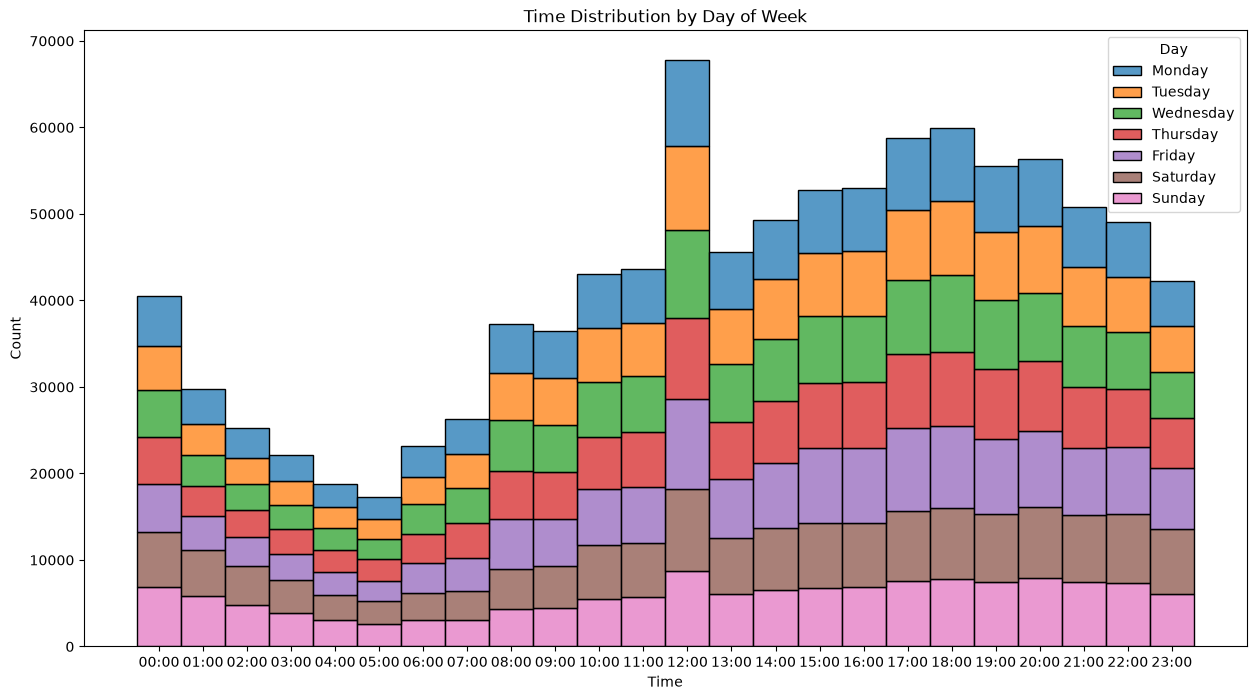

In [37]:
sorted_df = df.sort_values(by='RoundedTime', ascending=True)
sorted_df
plt.figure(figsize=(15, 8))
sns.histplot(data=sorted_df, x='RoundedTime', hue='Day', multiple='stack', binwidth=1, hue_order=days)
plt.title('Time Distribution by Day of Week')
plt.xlabel('Time')
plt.ylabel('Count')
plt.show()


# Impact of Major Events:
• Identify significant events or policy changes during the dataset period and analyze 
crime rate changes before and after these events

In [38]:
infoData.loc[13,'descriptions']

'Descent Code: A - Other Asian B - Black C - Chinese D - Cambodian F - Filipino G - Guamanian H - Hispanic/Latin/Mexican I - American Indian/Alaskan Native J - Japanese K - Korean L - Laotian O - Other P - Pacific Islander S - Samoan U - Hawaiian V - Vietnamese W - White X - Unknown Z - Asian Indian'

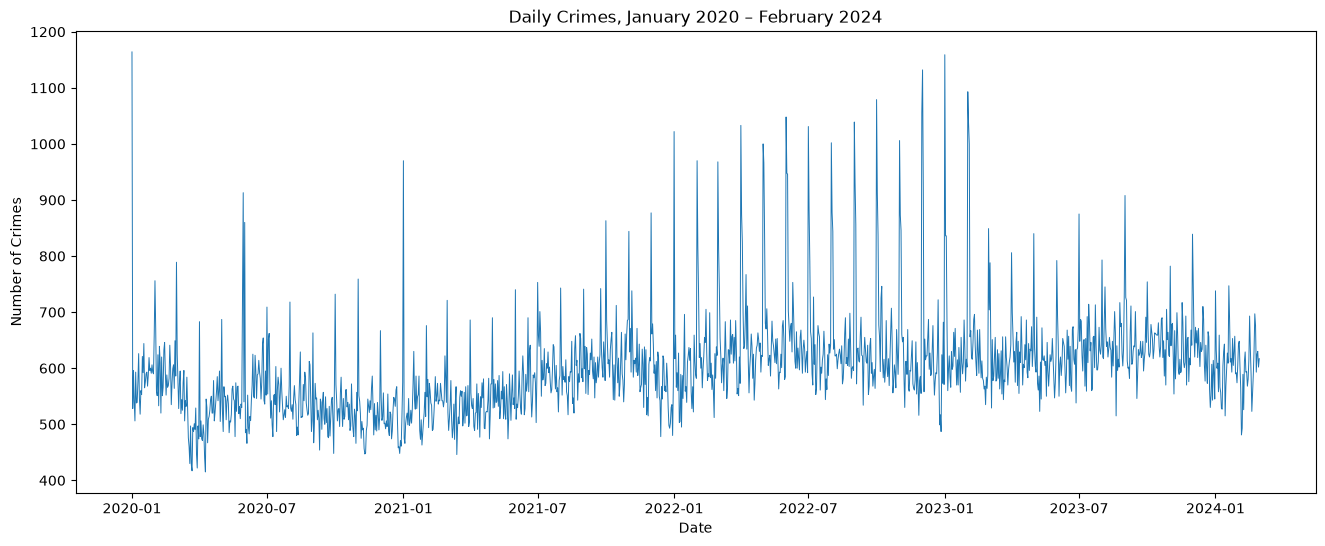

In [39]:
DateWiseCrimes = df_trend.groupby('DATE OCC').size()
plt.figure(figsize=(16, 6))
plt.plot(DateWiseCrimes.index, DateWiseCrimes.values, linewidth=0.7)
plt.xlabel("Date")
plt.ylabel("Number of Crimes")
plt.title("Daily Crimes, January 2020 – February 2024")
plt.show()

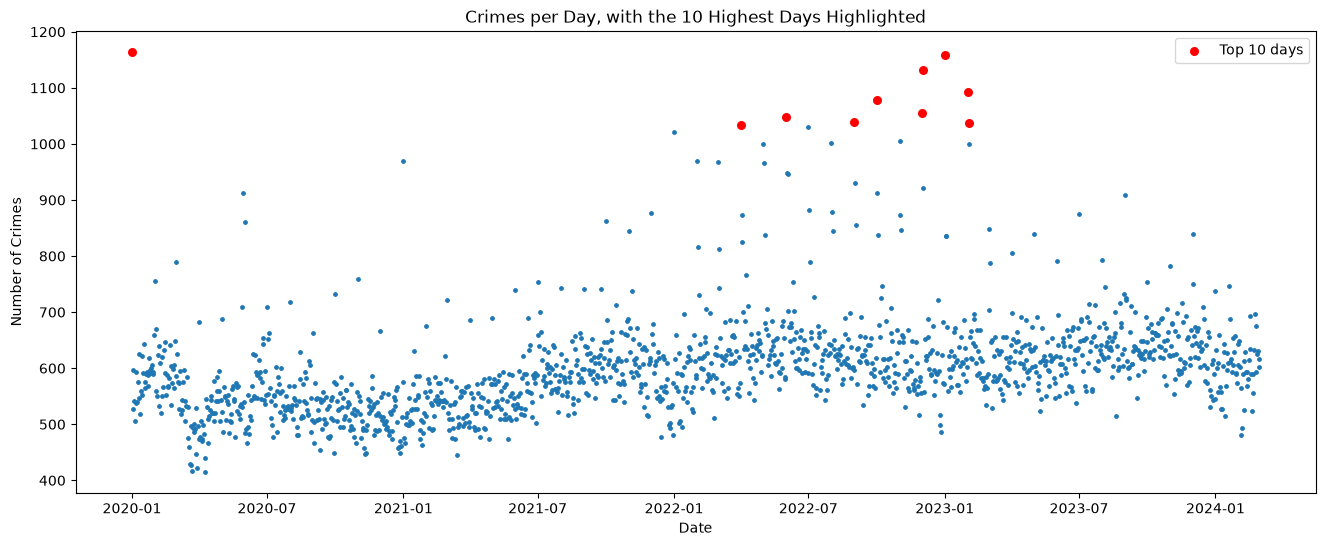

DATE OCC
2020-01-01    1164
2023-01-01    1159
2022-12-02    1132
2023-02-01    1093
2022-10-01    1079
2022-12-01    1056
2022-06-01    1048
2022-09-01    1039
2023-02-02    1038
2022-04-01    1033
dtype: int64

In [40]:
topCrimeDates = DateWiseCrimes.sort_values(ascending=False)
plt.figure(figsize=(16, 6))
plt.scatter(topCrimeDates.index, topCrimeDates.values, s=6)
plt.scatter(topCrimeDates.index[:10], topCrimeDates.values[:10], color='red', s=30, label='Top 10 days')
plt.title("Crimes per Day, with the 10 Highest Days Highlighted")
plt.xlabel("Date")
plt.ylabel("Number of Crimes")
plt.legend()
plt.show()
topCrimeDates[:10]

# 8. Outliers and Anomalies:
• Use statistical methods or data visualization techniques to identify dataset outliers 
and investigate unusual patterns

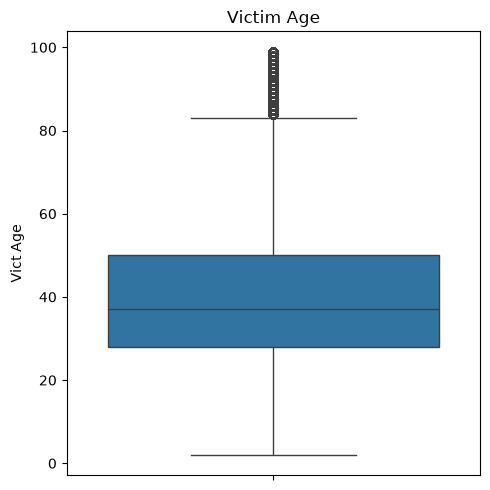

In [41]:
fig, axs = plt.subplots(1, 1, figsize=(5, 5))

plt1 = sns.boxplot(df['Vict Age'])
plt1.set_title("Victim Age")
# plt1.set_ylim(0, df['Vict Age'].max() + 10)
plt.tight_layout()
plt.show()



IQR bounds: -5 to 83 years
Outlier ages: 4,375 (0.59% of recorded ages)


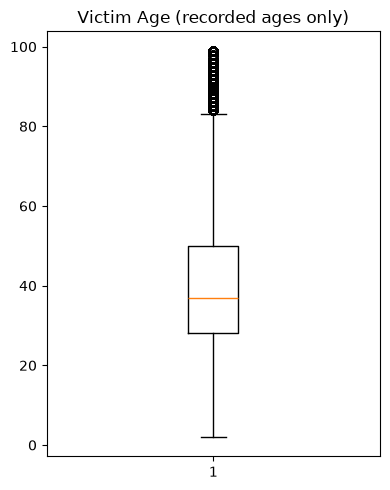

In [42]:
valid_ages = df['Vict Age'].dropna()
Q1, Q3 = valid_ages.quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = valid_ages[(valid_ages < lower) | (valid_ages > upper)]
print(f"IQR bounds: {lower:.0f} to {upper:.0f} years")
print(f"Outlier ages: {len(outliers):,} ({len(outliers) / len(valid_ages):.2%} of recorded ages)")

# Outliers are flagged, not dropped: an 85-year-old victim is unusual but real, and
# dropping rows here would also remove those crimes from every later analysis.
df['Age Outlier'] = df['Vict Age'].notna() & ~df['Vict Age'].between(lower, upper)

plt.figure(figsize=(4, 5))
plt.boxplot(valid_ages)
plt.title("Victim Age (recorded ages only)")
plt.tight_layout()
plt.show()

# 9. Demographic Factors:
• Analyze the dataset to identify any patterns or correlations

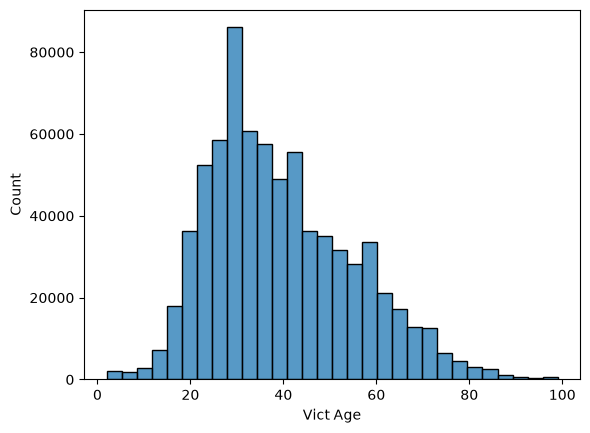

In [43]:
ages=df['Vict Age'].value_counts()
sns.histplot(df['Vict Age'],bins=30)
plt.show()

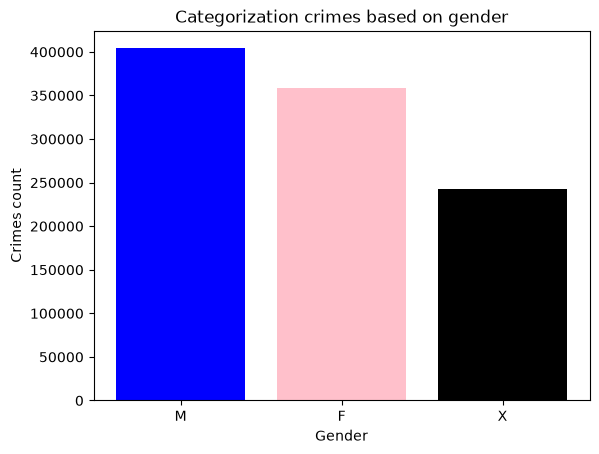

In [44]:

GenderData= df['Vict Sex'].value_counts()
plt.autoscale()
plt.bar(GenderData.index, GenderData.values,color=["b",'pink','black'])
plt.xlabel('Gender')
plt.ylabel('Crimes count')
plt.title('Categorization crimes based on gender')
plt.show()

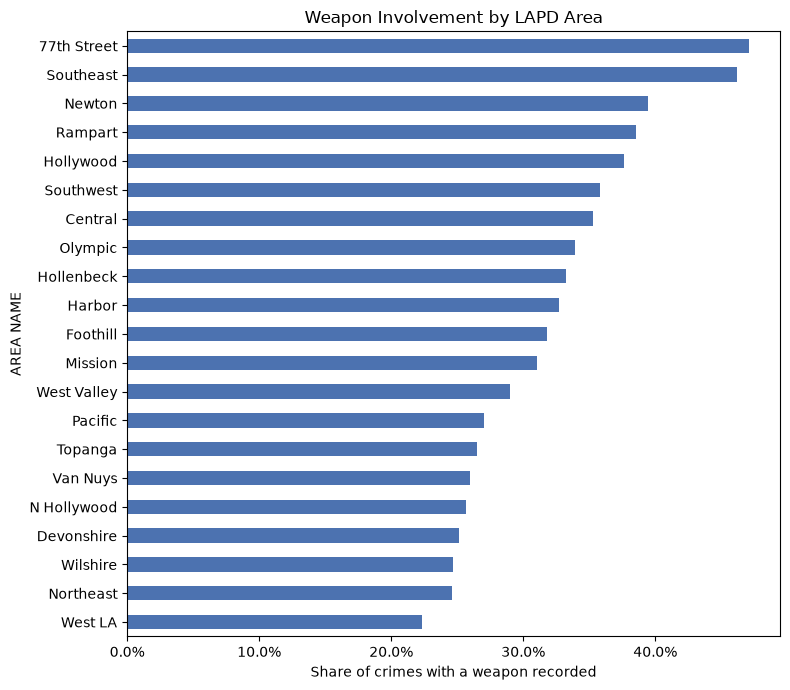

In [45]:
# Area, weapon code and age are codes/categories, so a correlation matrix of them is not meaningful.
# Instead: in which areas are weapons most often involved?
weapon_rate = (df['Weapon Desc'] != 'NO WEAPON RECORDED').groupby(df['AREA NAME']).mean().sort_values()
ax = weapon_rate.plot(kind='barh', figsize=(8, 7), color='#4C72B0')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xlabel('Share of crimes with a weapon recorded')
plt.title('Weapon Involvement by LAPD Area')
plt.tight_layout()
plt.show()

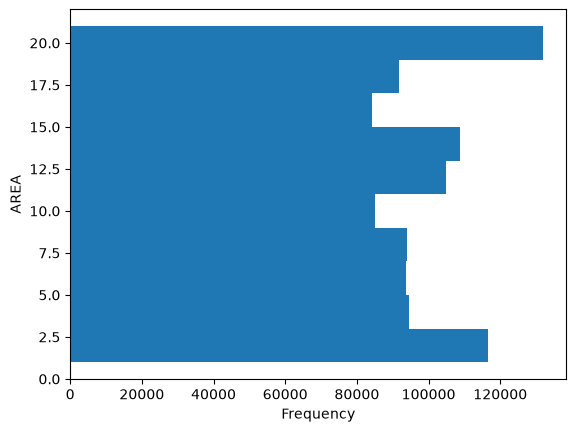

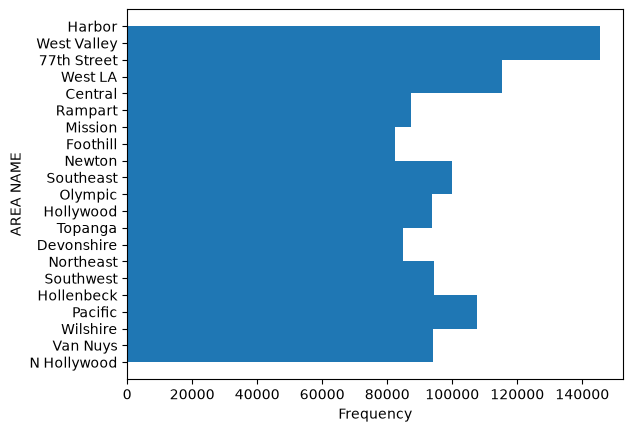

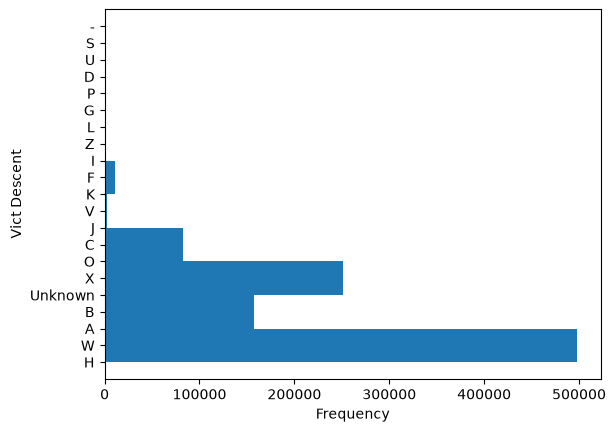

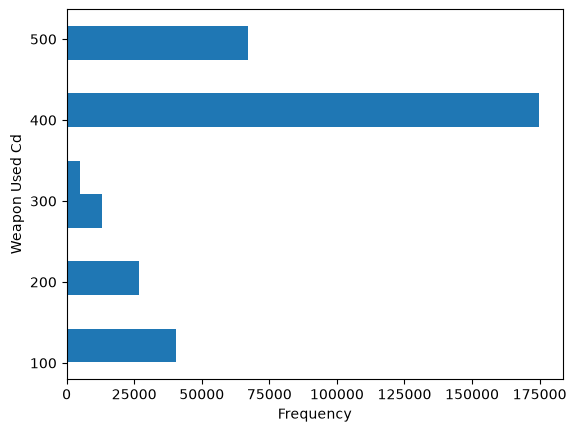

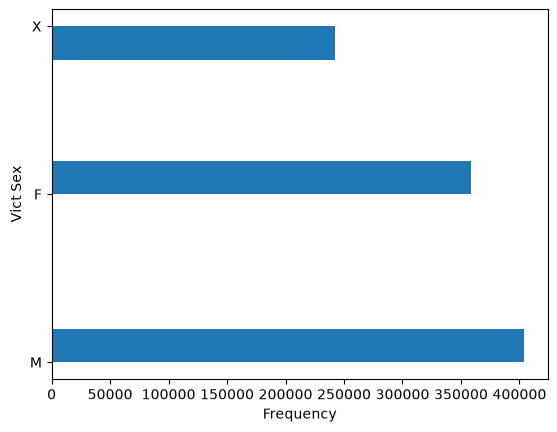

In [46]:
#categorical identified column from infoData
# ArEA,AreaName,VictDescent,Weapons used Cd--> value counts

# draw histograms of each categorical column to know the distribution of crimes 
for column in ['AREA','AREA NAME','Vict Descent','Weapon Used Cd','Vict Sex']:

    df[column].hist(orientation='horizontal')
    plt.ylabel(column)
    plt.xlabel("Frequency")
    plt.grid(False)
    plt.show()

In [47]:
topFiveCrimes=df['Crm Cd Desc'].value_counts()
topMostCrimesData=df[df['Crm Cd Desc'].isin(topFiveCrimes.index[:5])]
CrimesByGender= topMostCrimesData.groupby(by=['Crm Cd Desc','Vict Sex',]).size().reset_index(name='crime count')
CrimesByGender.groupby('Crm Cd Desc').size()

Crm Cd Desc
BATTERY - SIMPLE ASSAULT                                   3
BURGLARY FROM VEHICLE                                      3
THEFT OF IDENTITY                                          3
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)    3
VEHICLE - STOLEN                                           3
dtype: int64

<Figure size 3000x3000 with 0 Axes>

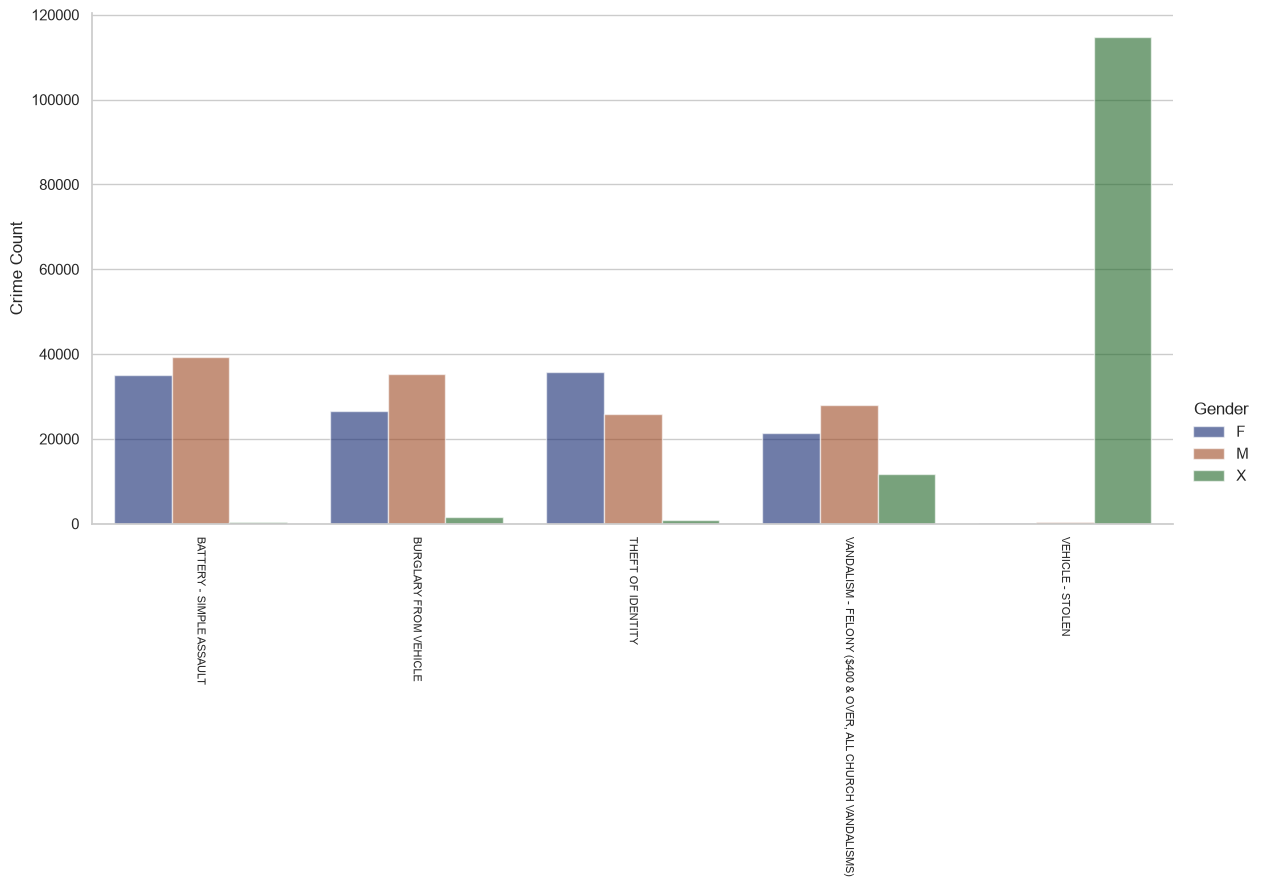

In [48]:
# plt.
plt.figure(figsize=(30,30))
sns.set_theme(style="whitegrid")
g=sns.catplot(
    data=CrimesByGender, kind="bar",
    x="Crm Cd Desc", y="crime count", hue="Vict Sex",
    errorbar="sd", palette="dark", alpha=.6, height=6,aspect=2
)

g.set_axis_labels("", "Crime Count")
g.legend.set_title("Gender")
plt.xticks(rotation=-90, fontsize=8)
plt.show()


In [49]:
# Victim age groups (non-overlapping); missing ages kept as their own group
def ageCategory(age):
    if pd.isna(age):
        return "Not recorded"
    if age < 20:
        return "Under 20"
    if age < 40:
        return "20–39"
    if age < 60:
        return "40–59"
    return "60+"

df['Age Category'] = df['Vict Age'].apply(ageCategory)
df['Age Category'].value_counts()

Age Category
20–39           374815
Not recorded    269360
40–59           228343
60+              90883
Under 20         41590
Name: count, dtype: int64

In [50]:
AgeCategoryCrimes = (df[df['Age Category'] != 'Not recorded']
                     .groupby(['Age Category', 'Crm Cd Desc']).size().reset_index(name='count')
                     .sort_values(by=['Age Category', 'count'], ascending=False))
# Top 5 crimes in each age category
top_5_crimes_per_age_category = AgeCategoryCrimes.groupby('Age Category').head(5).reset_index(drop=True)
top_5_crimes_per_age_category

,Age Category,Crm Cd Desc,count
0,Under 20,BATTERY - SIMPLE ASSAULT,6024
1,Under 20,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",4078
2,Under 20,CHILD ABUSE (PHYSICAL) - SIMPLE ASSAULT,3410
3,Under 20,ROBBERY,2457
4,Under 20,INTIMATE PARTNER - SIMPLE ASSAULT,1800
5,60+,BATTERY - SIMPLE ASSAULT,10897
6,60+,BURGLARY,9379
7,60+,THEFT OF IDENTITY,8678
8,60+,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",6111
9,60+,THEFT PLAIN - PETTY ($950 & UNDER),5995


<Figure size 3000x3000 with 0 Axes>

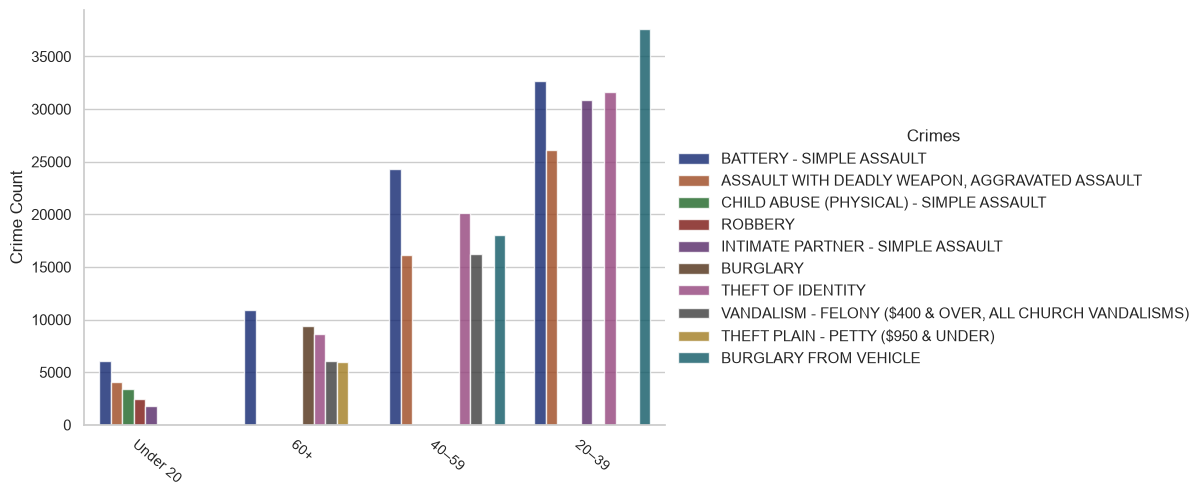

In [51]:
# plt.
plt.figure(figsize=(30,30))
sns.set_theme(style="whitegrid")
g=sns.catplot(
    data=top_5_crimes_per_age_category, kind="bar",
    x="Age Category", y="count", hue="Crm Cd Desc",
    errorbar="sd", palette="dark", alpha=.8,aspect=1.5
)

g.set_axis_labels("", "Crime Count")
g.legend.set_title("Crimes")
plt.xticks(rotation=-40, fontsize=10)
plt.show()


In [52]:
locationWiseCrimes= df.groupby(['LAT','LON','LOCATION']).size().reset_index(name='Crimes Count').sort_values(by=['Crimes Count'],ascending=False)
locationWiseCrimes

,LAT,LON,LOCATION,Crimes Count
81503,34.0561,-118.2375,800 N ALAMEDA ST,2396
74233,34.0483,-118.2631,700 S FIGUEROA ST,1657
68263,34.0428,-118.4582,11800 SANTA MONICA BL,1448
152003,34.2440,-118.5583,9300 TAMPA AV,1434
93027,34.0736,-118.3563,100 THE GROVE DR,1362
...,...,...,...,...
78064,34.0523,-118.2502,300 S OLIVE ST,1
78063,34.0523,-118.2537,700 W 4TH ST,1
78062,34.0523,-118.2537,4TH,1
78061,34.0523,-118.2571,FIGUEROA,1


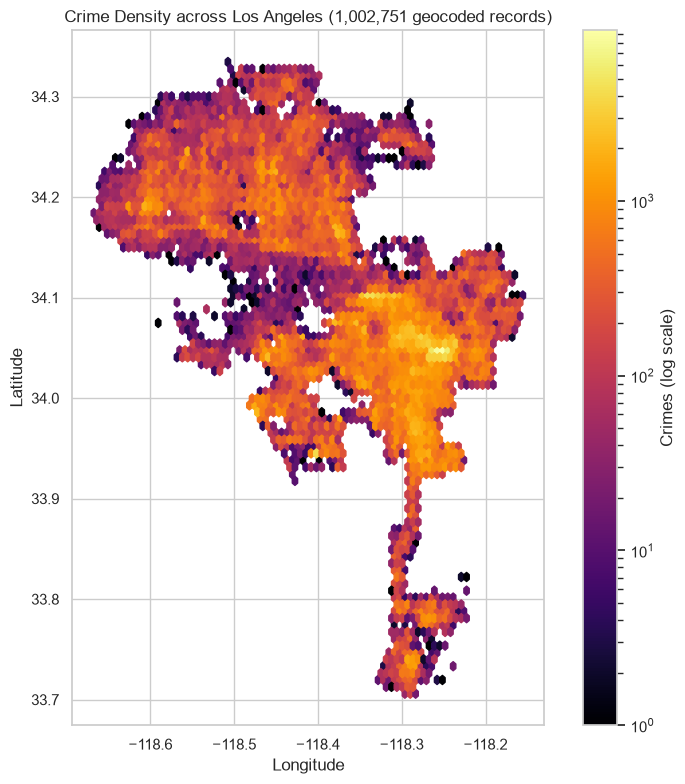

In [53]:
# Crime density across the city (all geocoded records)
fig, ax = plt.subplots(figsize=(8, 8))
hb = ax.hexbin(geo['LON'], geo['LAT'], gridsize=80, bins='log', cmap='inferno', mincnt=1)
fig.colorbar(hb, ax=ax, label='Crimes (log scale)')
ax.set_title(f'Crime Density across Los Angeles ({len(geo):,} geocoded records)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect(1.2)
plt.tight_layout()
plt.show()

# 10. Predicting Future Trends:
• Employ time series forecasting methods, such as ARIMA or Prophet, to predict 
future crime trends based on historical data. Consider incorporating relevant 
external factors into your models

In [54]:
from prophet import Prophet

# Daily crime counts, restricted to the period before the records-system change
daily = (df_trend.groupby('DATE OCC').size()
         .reset_index(name='y').rename(columns={'DATE OCC': 'ds'}))

split_date = '2023-07-01'
train = daily[daily.ds < split_date]
test = daily[daily.ds >= split_date]
print(f"Train: {train.ds.min():%Y-%m-%d} to {train.ds.max():%Y-%m-%d} ({len(train)} days)")
print(f"Test:  {test.ds.min():%Y-%m-%d} to {test.ds.max():%Y-%m-%d} ({len(test)} days)")

Train: 2020-01-01 to 2023-06-30 (1277 days)
Test:  2023-07-01 to 2024-02-29 (244 days)


In [55]:
# Fit on the training period only, so the test months are genuinely unseen
model = Prophet(weekly_seasonality=True, yearly_seasonality=True)
model.fit(train)
pred = model.predict(test[['ds']])

errors = pred['yhat'].values - test['y'].values
mae = np.abs(errors).mean()
mape = (np.abs(errors) / test['y'].values).mean()
baseline_mae = (test['y'] - train['y'].tail(28).mean()).abs().mean()

print(f"Mean daily crimes in test period: {test['y'].mean():.0f}")
print(f"Prophet  MAE: {mae:.1f} crimes/day  (MAPE {mape:.1%})")
print(f"Baseline MAE: {baseline_mae:.1f} crimes/day  (average of the last 28 training days)")

20:59:13 - cmdstanpy - INFO - Chain [1] start processing


20:59:13 - cmdstanpy - INFO - Chain [1] done processing


Mean daily crimes in test period: 633
Prophet  MAE: 36.5 crimes/day  (MAPE 5.6%)
Baseline MAE: 42.2 crimes/day  (average of the last 28 training days)


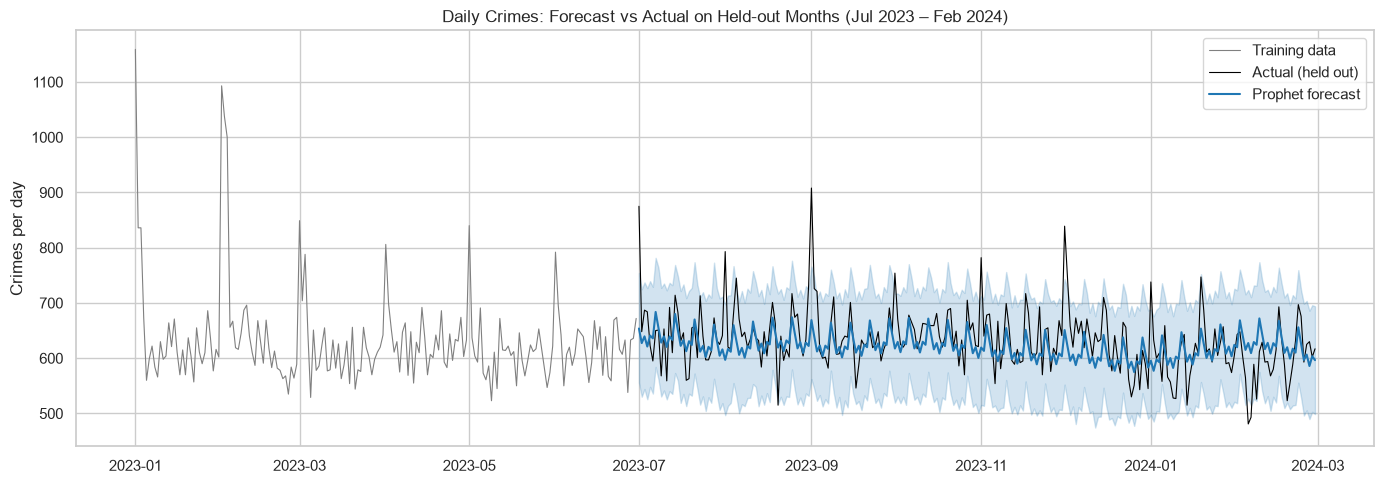

In [56]:
fig, ax = plt.subplots(figsize=(14, 5))
recent = train[train.ds >= '2023-01-01']
ax.plot(recent.ds, recent.y, color='grey', lw=0.8, label='Training data')
ax.plot(test.ds, test.y, color='black', lw=0.8, label='Actual (held out)')
ax.plot(pred.ds, pred.yhat, color='tab:blue', lw=1.5, label='Prophet forecast')
ax.fill_between(pred.ds, pred.yhat_lower, pred.yhat_upper, color='tab:blue', alpha=0.2)
ax.set_title('Daily Crimes: Forecast vs Actual on Held-out Months (Jul 2023 – Feb 2024)')
ax.set_ylabel('Crimes per day')
ax.legend()
plt.tight_layout()
plt.show()

20:59:13 - cmdstanpy - INFO - Chain [1] start processing


20:59:13 - cmdstanpy - INFO - Chain [1] done processing


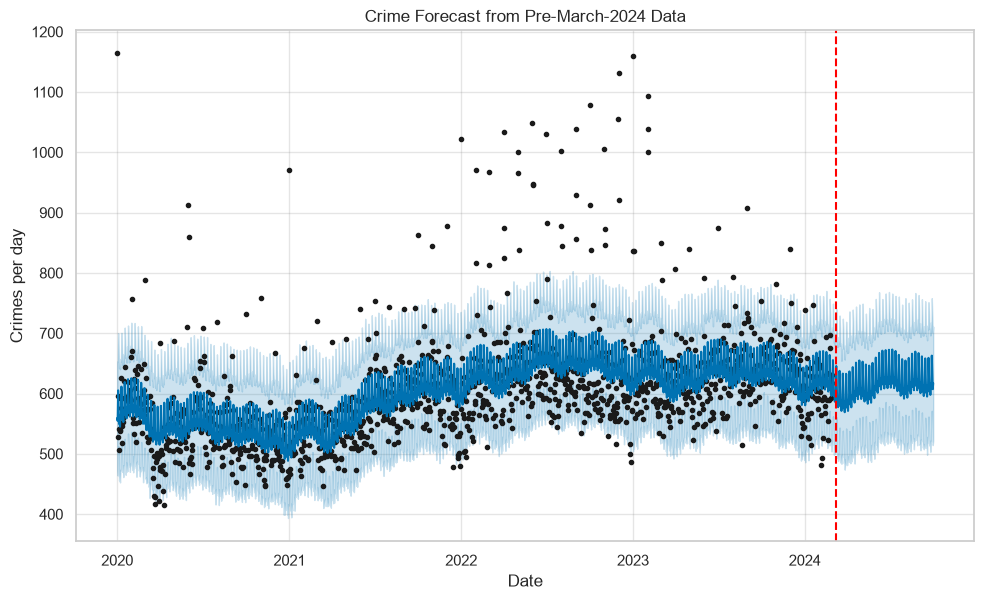

,Expected (forecast),Recorded in dataset,Recorded vs expected
2024-04,18124.0,12946,-29%
2024-05,18914.0,9386,-50%
2024-06,18853.0,8126,-57%
2024-07,19322.0,8170,-58%
2024-08,19341.0,8324,-57%
2024-09,18565.0,8309,-55%


In [57]:
# Refit on all clean data and project the following months. Comparing this with what the
# dataset recorded after March 2024 sizes the gap left by the records-system change.
full_model = Prophet(weekly_seasonality=True, yearly_seasonality=True).fit(daily)
future = full_model.make_future_dataframe(periods=214)  # through September 2024
forecast = full_model.predict(future)

full_model.plot(forecast)
plt.axvline(pd.Timestamp('2024-03-07'), color='red', linestyle='--')
plt.title('Crime Forecast from Pre-March-2024 Data')
plt.xlabel('Date')
plt.ylabel('Crimes per day')
plt.show()

window = slice('2024-04-01', '2024-09-30')
expected = forecast.set_index('ds')['yhat'].loc[window]
expected = expected.groupby(expected.index.to_period('M')).sum().round()
recorded = df[df['DATE OCC'].between('2024-04-01', '2024-09-30')]
recorded = recorded.groupby(recorded['DATE OCC'].dt.to_period('M')).size()
comparison = pd.DataFrame({'Expected (forecast)': expected, 'Recorded in dataset': recorded})
comparison['Recorded vs expected'] = (comparison['Recorded in dataset'] / comparison['Expected (forecast)'] - 1).map('{:+.0%}'.format)
comparison

## Export for the Power BI dashboard
A cleaned table with readable columns, written to `../data/` (not committed). `In Trend Period` marks records before the March 2024 records-system change.

In [58]:
export_cols = ['DATE OCC', 'Year', 'Month', 'Day', 'RoundedTime', 'AREA NAME', 'Crm Cd Desc', 'Premis Desc',
               'Weapon Desc', 'Vict Age', 'Age Category', 'Vict Sex', 'LAT', 'LON']
crime_export = df[export_cols].copy()
crime_export['In Trend Period'] = crime_export['DATE OCC'] <= TREND_END
crime_export.loc[(crime_export['LAT'] == 0) | (crime_export['LON'] == 0), ['LAT', 'LON']] = np.nan
crime_export.to_csv(DATA_DIR / "crime_dashboard_data.csv", index=False)
crime_export.shape

(1004991, 15)